# 02 · Outcome distributions: decisions as variance tools

In 21 Rivals you do not win by having the most chips on average; you win by finishing **above one opponent** after 5 rounds on the same cards. The project's objective is P(win) + 5/9·P(tie) (a tie refunds the entry fee, a win pays 1.8×). A player who is behind wants more variance and a player who is ahead wants less, so each decision is worth looking at as a **distribution of outcomes**, not just an expected value.

This notebook only calls the engine. It shows:
1. the full outcome distribution of every legal action for a set of instructive decisions (`Solver.evaluate`);
2. across every two-card hand and upcard, how much expected value it costs to buy or shed variance with play deviations, weighted by how often each spot is dealt;
3. the distribution of a whole round, and what flat betting 10, 100, 250 or 500 chips does to a 5-round match (`rivals.match.play_player`);
4. the two side bets, Perfect Pairs and 4-Card Total, as variance tools next to the main bet.

Units: **net units of the starting bet** (a doubled win is +2, a split where both hands double and win is +4) unless stated as chips. EV is the expected net; SD is the standard deviation of the net. Rules are the confirmed 21 Rivals rules (`DEFAULT_RULES`): 6 decks, dealer stands on 17, double only on 9–11 (A,8 and A,9 count), no blackjack check under a ten, one split, split aces may be hit.

In [1]:
import sys, pathlib, time, logging, random, re
from collections import Counter
from itertools import combinations

try:
    import rivals
except ImportError:  # kernel started without the project's editable install on its path
    sys.path.insert(0, str(pathlib.Path.cwd().parent))
    import rivals

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from rivals import DEFAULT_RULES
from rivals.agents import Agent
from rivals.cards import RANK, fresh_decks
from rivals.hand import Action
from rivals.match import play_player
from rivals.resolve import play_round
from rivals.shoe import Shoe, match_shoes
from rivals.side_bets import SideBets, four_card_total, four_card_total_payout, perfect_pairs_payout
from rivals.solver import BasicStrategy, Solver, basic_chart, solver_for
from rivals.solver.exact import ACE, TEN, VALUE_NAMES, counts_of, value_index

%matplotlib inline
%config InlineBackend.figure_formats = ["png"]
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SURFACE, NEUTRAL, CRITICAL = "#fcfcfb", "#f0efec", "#d03b3b"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
ACTIONS = [Action.STAND, Action.HIT, Action.DOUBLE, Action.SPLIT]
NAME = {Action.STAND: "Stand", Action.HIT: "Hit", Action.DOUBLE: "Double", Action.SPLIT: "Split"}
COLOR = {Action.STAND: BLUE, Action.HIT: YELLOW, Action.DOUBLE: GREEN, Action.SPLIT: MAGENTA}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "legend.frameon": False, "legend.fontsize": 9,
})
pd.set_option("display.width", 160)


def minus(text):
    # Typographic minus sign in front of numbers in labels built with f-strings.
    return re.sub(r"-(?=[\d.])", "\u2212", str(text))


RULES = DEFAULT_RULES
t0 = time.perf_counter()
solver = solver_for(RULES)          # optimal play
chart = basic_chart(RULES)          # the basic-strategy chart derived from it
chart_round = Solver(RULES, strategy=chart).round_value()
print(f"solved in {time.perf_counter() - t0:.0f} s: chart play EV {chart_round.ev:+.3%}, SD {chart_round.std:.3f} per round")

solved in 13 s: chart play EV -0.476%, SD 1.105 per round


## 1. Every action's full distribution, for instructive decisions

`solver.evaluate(cards, upcard).actions[action].dist` is the exact probability of each net result if you take that action now and play on optimally. One figure per decision; the legend gives each action's EV and SD, and the title names the highest-EV play. Specific two-card hands are used (a hard 16 is shown as T-6, the most common way to hold it), because the exact values depend slightly on the cards.

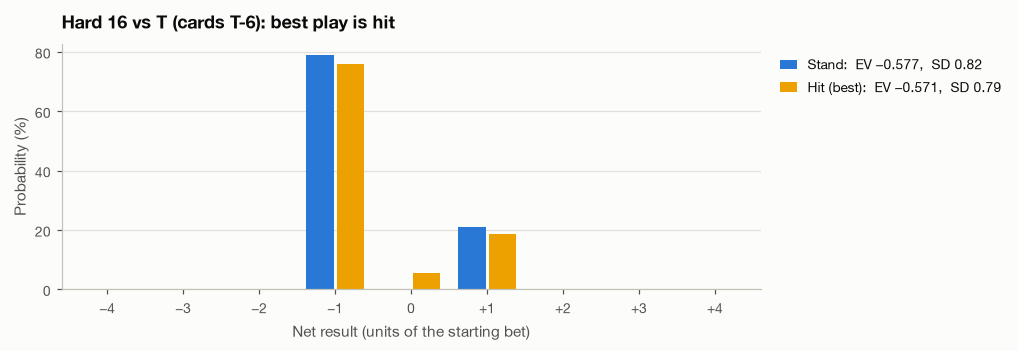

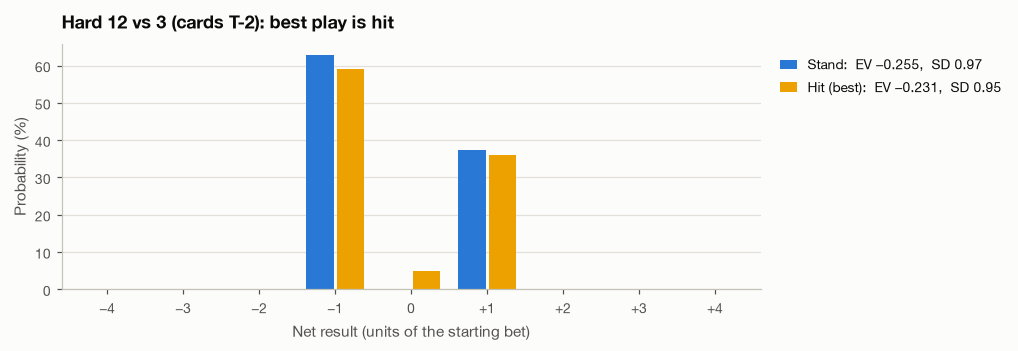

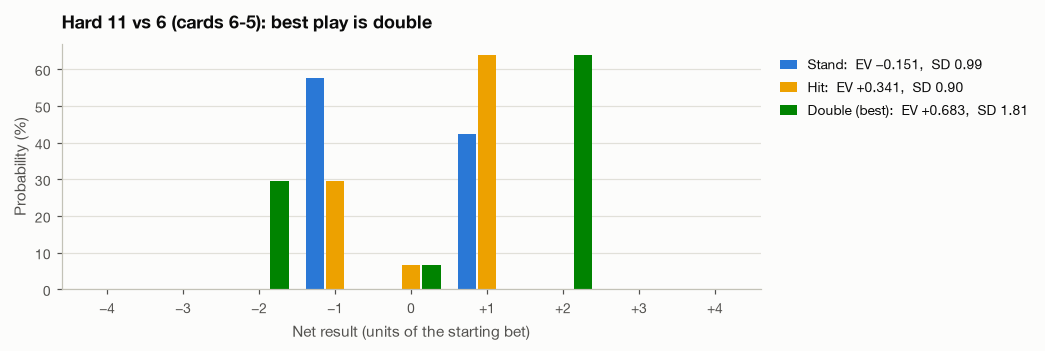

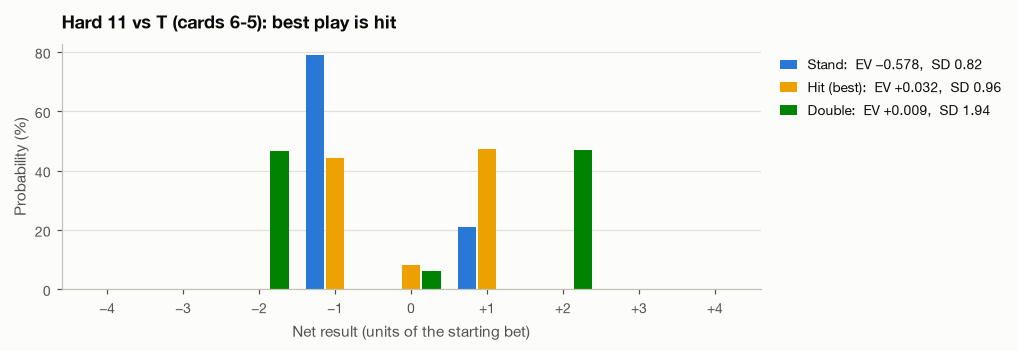

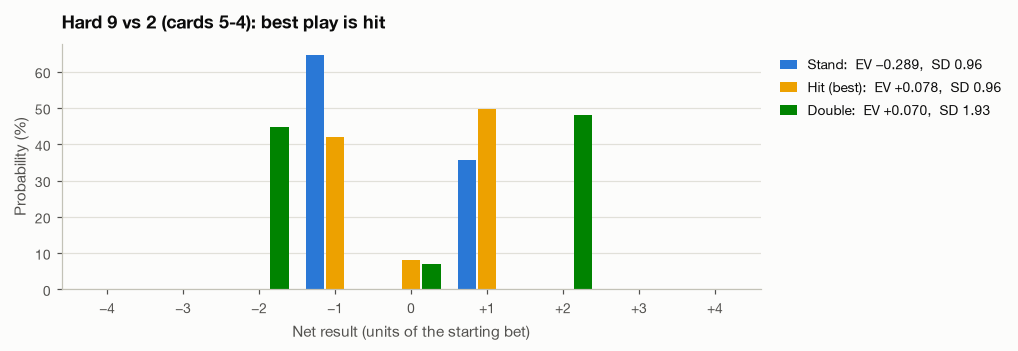

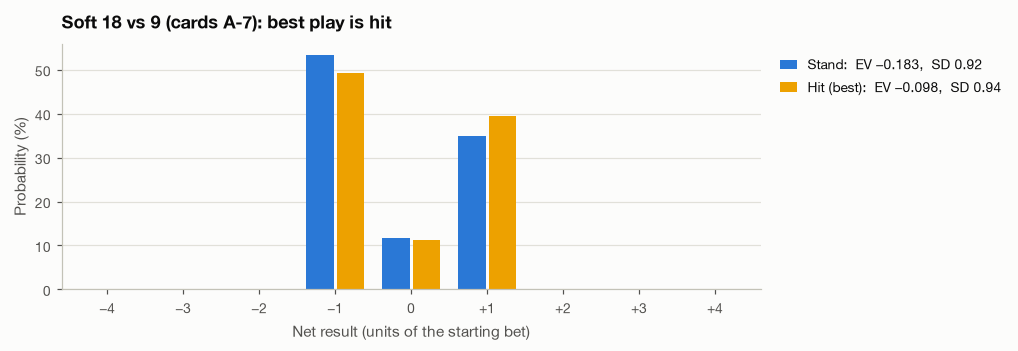

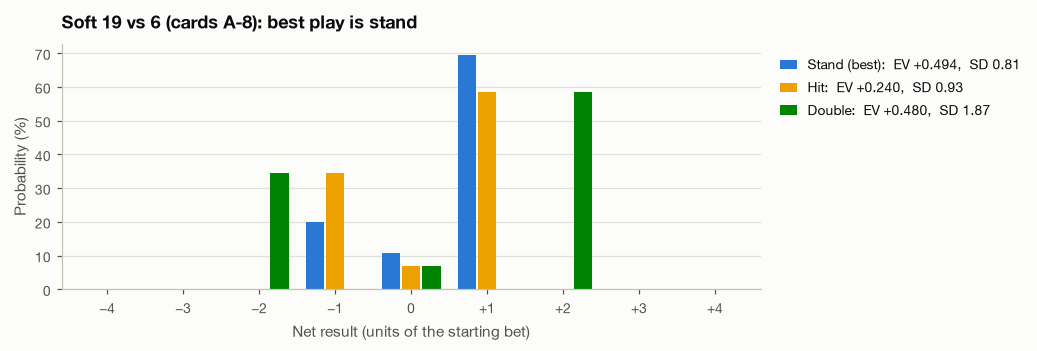

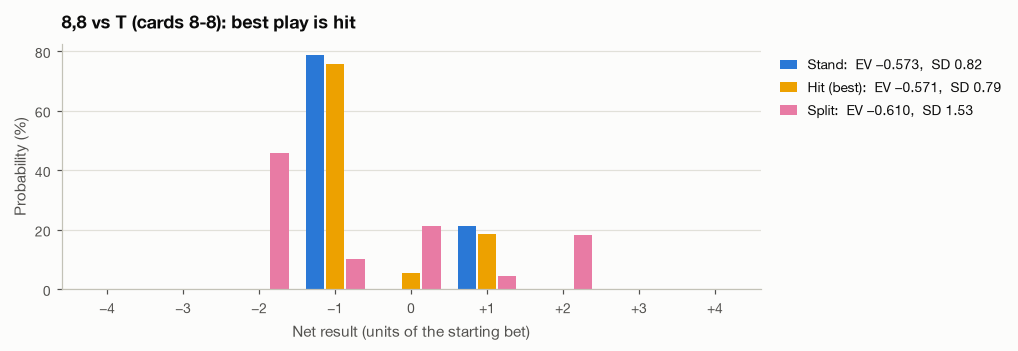

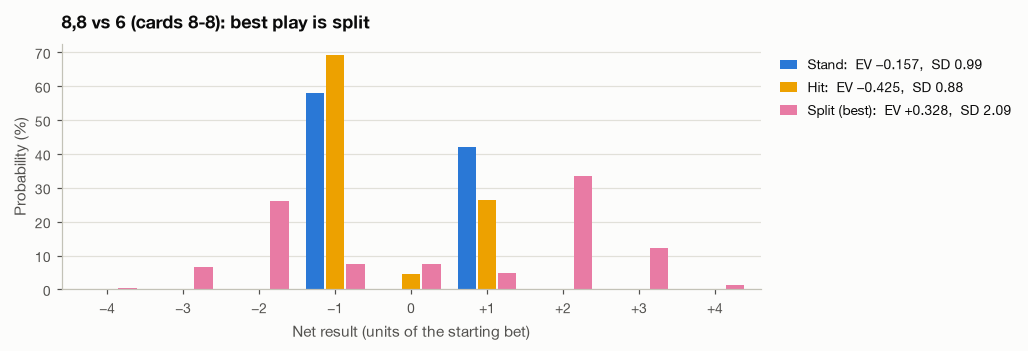

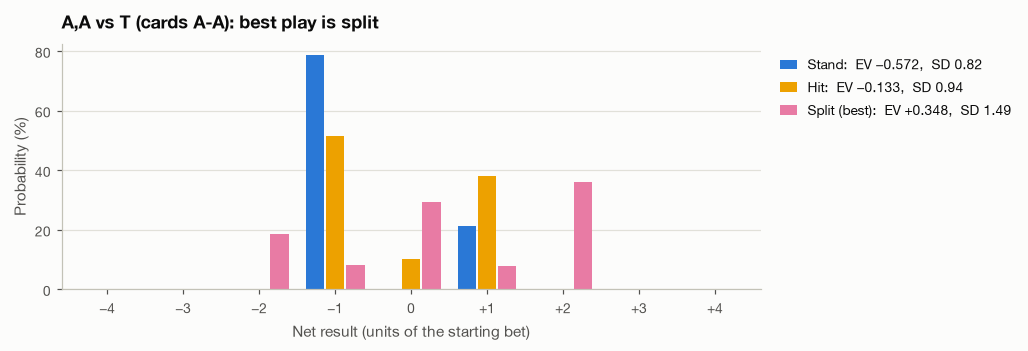

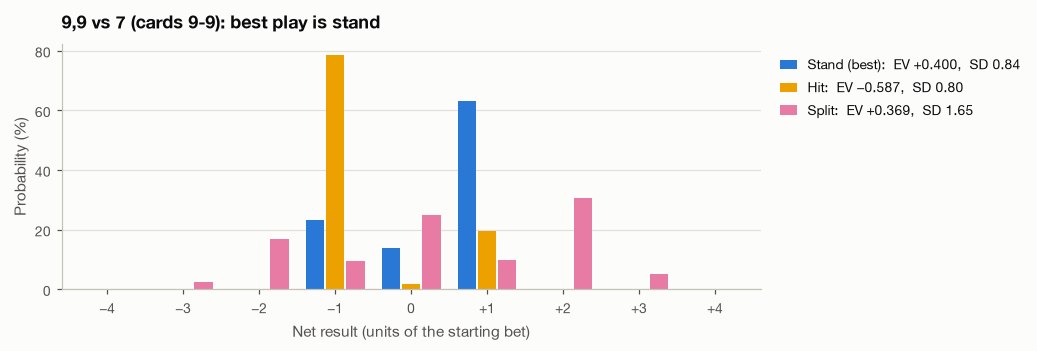

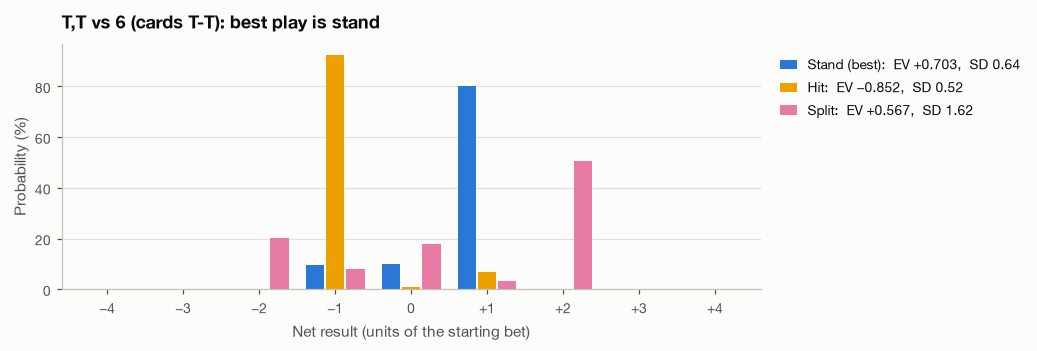

In [2]:
DECISIONS = [  # (description, player cards, dealer upcard)
    ("Hard 16 vs T", "Ts 6d", "Tc"),
    ("Hard 12 vs 3", "Ts 2d", "3c"),
    ("Hard 11 vs 6", "6s 5d", "6c"),
    ("Hard 11 vs T", "6s 5d", "Tc"),
    ("Hard 9 vs 2", "5s 4d", "2c"),
    ("Soft 18 vs 9", "As 7d", "9c"),
    ("Soft 19 vs 6", "As 8d", "6c"),
    ("8,8 vs T", "8s 8d", "Tc"),
    ("8,8 vs 6", "8s 8d", "6c"),
    ("A,A vs T", "As Ad", "Tc"),
    ("9,9 vs 7", "9s 9d", "7c"),
    ("T,T vs 6", "Ts Td", "6c"),
]
NETS = np.arange(-4, 5)
NET_LABELS = [minus(f"{x:+d}") if x else "0" for x in NETS]


def hand_label(cards):
    return "-".join(c[0] for c in cards.split())


def plot_decision(title, cards, upcard):
    result = solver.evaluate(cards, upcard)
    acts = [a for a in ACTIONS if a in result.actions]
    width = 0.8 / len(acts)
    fig, ax = plt.subplots(figsize=(8.2, 2.9))
    for i, a in enumerate(acts):
        v = result.actions[a]
        probs = np.array([v.dist.get(float(x), 0.0) for x in NETS])
        label = f"{NAME[a]}{' (best)' if a == result.best else ''}:  EV {v.ev:+.3f},  SD {v.std:.2f}"
        ax.bar(NETS + (i - (len(acts) - 1) / 2) * width, 100 * probs, width=width * 0.9,
               color=COLOR[a], label=minus(label))
    ax.set_xticks(NETS, NET_LABELS)
    ax.set_xlim(-4.6, 4.6)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_ylabel("Probability (%)")
    ax.set_xlabel("Net result (units of the starting bet)")
    ax.set_title(f"{title} (cards {hand_label(cards)}): best play is {NAME[result.best].lower()}")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), handlelength=1.2)
    plt.show()
    return result


evaluations = {}
for title, cards, upcard in DECISIONS:
    evaluations[title] = plot_decision(title, cards, upcard)

The same numbers as a table (P(lose) and P(win) add up every losing or winning result, whatever its size):

In [3]:
rows = []
for title, result in evaluations.items():
    for a in ACTIONS:
        if a not in result.actions:
            continue
        v = result.actions[a]
        rows.append({"decision": title, "action": NAME[a] + (" *" if a == result.best else ""),
                     "EV": v.ev, "SD": v.std,
                     "P(lose)": sum(p for x, p in v.dist.items() if x < 0),
                     "P(push)": v.dist.get(0.0, 0.0),
                     "P(win)": sum(p for x, p in v.dist.items() if x > 0),
                     "worst": min(v.dist), "best": max(v.dist)})
decision_table = pd.DataFrame(rows).set_index(["decision", "action"])
decision_table.style.format({"EV": "{:+.3f}", "SD": "{:.2f}", "P(lose)": "{:.1%}", "P(push)": "{:.1%}",
                             "P(win)": "{:.1%}", "worst": "{:+.0f}", "best": "{:+.0f}"})

**What to notice** (`*` marks the best play):

* **Doubling and splitting are the variance actions.** They stretch the outcome range from ±1 to ±2 (doubles) or ±4 (a split with doubles after it). Hard 11 vs 6 doubles its EV and its SD together.
* **Hard 11 vs T and hard 9 vs 2 are near coin-flips between hitting and doubling.** Doubling costs only 0.022 units against a ten (the hidden blackjack is part of the reason it is not the best play here) and 0.008 against a 2, while roughly doubling the SD. These are the cheapest variance a player can buy with a play.
* **Soft 19 vs 6 can double in 21 Rivals** (A,8 shows 9). Standing is better by 0.014 units, but doubling buys about 1.06 extra units of SD for that.
* **Hitting can be the *low*-variance play.** Hard 16 vs T and hard 12 vs 3: hitting creates pushes, so its SD is lower than standing's. Standing on 16 vs T is a (tiny) variance-adding deviation that costs 0.006 units.
* **8,8 vs T:** with no check under a ten, splitting is worse than hitting by 0.04 units. It buys about 0.74 units of SD, and almost all of the extra spread is on the losing side (−2 has a 46% chance).
* **T,T vs 6:** splitting tens is the classic "big swing" play. It gives up 0.14 units against standing on 20 and still has a positive EV.

## 2. EV cost vs variance across every two-card hand and upcard

For each of the 540 decisions (54 two-card hands × 10 upcards; ace-ten is a blackjack and has no decision) the solver gives every legal action's EV and SD. Two deviations are measured against the best play:

* **adding variance:** take the legal action with the *highest* SD instead of the best one;
* **shedding variance:** take the legal action with the *lowest* SD.

The price of a deviation is the EV it gives up, and its yield is the change in SD. **Cost per unit of SD** (EV given up ÷ SD gained or shed, in % of the bet) ranks them.

**How often is each spot dealt?** The engine computes deal probabilities inside `Solver.round_value()` but does not expose them, so they are measured instead: 600,000 rounds of basic strategy are played through `play_round` on seeded shoes with a policy that records each round's first decision. This counts only decisions actually reached (no player blackjack, and no dealer blackjack under a checked ace). The same rounds carry a 5-chip Perfect Pairs and a 5-chip 4-Card Total bet, used in section 4. The run takes about 25 seconds.

In [4]:
class FirstDecision:
    # Plays the basic-strategy chart; remembers the round's first decision as (two-card hand, upcard) values.
    def __init__(self, rules):
        self.policy = BasicStrategy(rules)
        self.first = None

    def act(self, ctx):
        if self.first is None:
            self.first = (tuple(sorted(value_index(c) for c in ctx.hand.cards)), value_index(ctx.upcard))
        return self.policy.act(ctx)

    def take_insurance(self, ctx):
        return False


N_ROUNDS, SEED, BET = 600_000, 2026, 10
SIDE = SideBets(perfect_pairs=5, four_card_total=5)
recorder = FirstDecision(RULES)
first_counts = Counter()
main_net, pp_net, fct_net = np.empty(N_ROUNDS), np.empty(N_ROUNDS), np.empty(N_ROUNDS)
t0 = time.perf_counter()
for i in range(N_ROUNDS):
    recorder.first = None
    r = play_round(Shoe.from_seed([SEED, i], RULES.num_decks), recorder, BET, SIDE, rules=RULES)
    main_net[i] = r.main_net / BET
    pp_net[i] = r.perfect_pairs_net / SIDE.perfect_pairs
    fct_net[i] = r.four_card_total_net / SIDE.four_card_total
    if recorder.first is not None:
        first_counts[recorder.first] += 1
print(f"{N_ROUNDS:,} rounds in {time.perf_counter() - t0:.0f} s; a decision was reached in "
      f"{sum(first_counts.values()) / N_ROUNDS:.1%} of rounds; {len(first_counts)} distinct (hand, upcard) spots seen")

600,000 rounds in 19 s; a decision was reached in 93.0% of rounds; 540 distinct (hand, upcard) spots seen


In [5]:
def situation_name(a, b, up, total, soft):
    if a == b:
        return f"{VALUE_NAMES[a]},{VALUE_NAMES[a]} vs {VALUE_NAMES[up]}"
    return f"{'soft' if soft else 'hard'} {total} vs {VALUE_NAMES[up]}"


rows = []
for a in range(10):
    for b in range(a, 10):
        if (a, b) == (ACE, TEN):
            continue  # blackjack: no decision
        for up in range(10):
            result = solver.evaluate_counts(counts_of([a, b]), up)
            acts = result.actions
            hi = max(acts, key=lambda x: acts[x].std)
            lo = min(acts, key=lambda x: acts[x].std)
            rows.append({
                "situation": situation_name(a, b, up, result.total, result.soft),
                "hand": f"{VALUE_NAMES[b]}-{VALUE_NAMES[a]}" if a != b else f"{VALUE_NAMES[a]}-{VALUE_NAMES[a]}",
                "total": result.total, "soft": result.soft, "pair": a if a == b else -1, "up": up,
                "best": NAME[result.best], "ev_best": acts[result.best].ev, "sd_best": acts[result.best].std,
                "hi": NAME[hi], "ev_hi": acts[hi].ev, "sd_hi": acts[hi].std,
                "lo": NAME[lo], "ev_lo": acts[lo].ev, "sd_lo": acts[lo].std,
                "freq": first_counts[((a, b), up)] / N_ROUNDS,
            })
spots = pd.DataFrame(rows)
print(f"{len(spots)} decisions; frequencies sum to {spots.freq.sum():.3f} decisions per round")
print(f"best play is already the highest-variance action in {(spots.hi == spots.best).sum()} of them "
      f"and the lowest-variance action in {(spots.lo == spots.best).sum()}")


def deviations(spots, alt):
    # One row per decision where the highest-SD ('hi') or lowest-SD ('lo') action is not the best play.
    d = spots[spots[alt] != spots.best].copy()
    d["action"] = d[alt]
    d["cost"] = d.ev_best - d[f"ev_{alt}"]
    d["dsd"] = (d[f"sd_{alt}"] - d.sd_best).abs()
    d["cost_per_sd"] = d.cost / d.dsd
    return d


def grouped(dev):
    # Merge hands that are the same chart cell with the same best play and deviation (e.g. 2-7, 3-6, 4-5 vs 2),
    # weighting by how often each is dealt.
    dev = dev.assign(w_cost=dev.freq * dev.cost, w_dsd=dev.freq * dev.dsd)
    g = dev.groupby(["situation", "total", "soft", "pair", "up", "best", "action"], as_index=False).agg(
        hands=("hand", ", ".join), freq=("freq", "sum"), w_cost=("w_cost", "sum"), w_dsd=("w_dsd", "sum"),
        cost_plain=("cost", "mean"), dsd_plain=("dsd", "mean"))
    seen = g.freq > 0
    g["cost"] = np.where(seen, g.w_cost / g.freq.where(seen, 1), g.cost_plain)
    g["dsd"] = np.where(seen, g.w_dsd / g.freq.where(seen, 1), g.dsd_plain)
    g["cost_per_sd"] = g.cost / g.dsd
    return g.drop(columns=["w_cost", "w_dsd", "cost_plain", "dsd_plain"]).sort_values("cost_per_sd").reset_index(drop=True)


add, shed = deviations(spots, "hi"), deviations(spots, "lo")
add_groups, shed_groups = grouped(add), grouped(shed)
print(f"variance-adding deviations: {len(add)} decisions ({len(add_groups)} chart cells); "
      f"variance-shedding: {len(shed)} decisions ({len(shed_groups)} chart cells)")

540 decisions; frequencies sum to 0.930 decisions per round
best play is already the highest-variance action in 377 of them and the lowest-variance action in 90
variance-adding deviations: 163 decisions (119 chart cells); variance-shedding: 450 decisions (265 chart cells)


**The map.** Each dot is one decision; its area is how often that spot is dealt. Grey diagonals are lines of equal cost per unit of SD: dots below the 1% line buy (or shed) SD for less than 1% of the bet per unit. Both axes are logarithmic. The cheapest deviations are labelled.

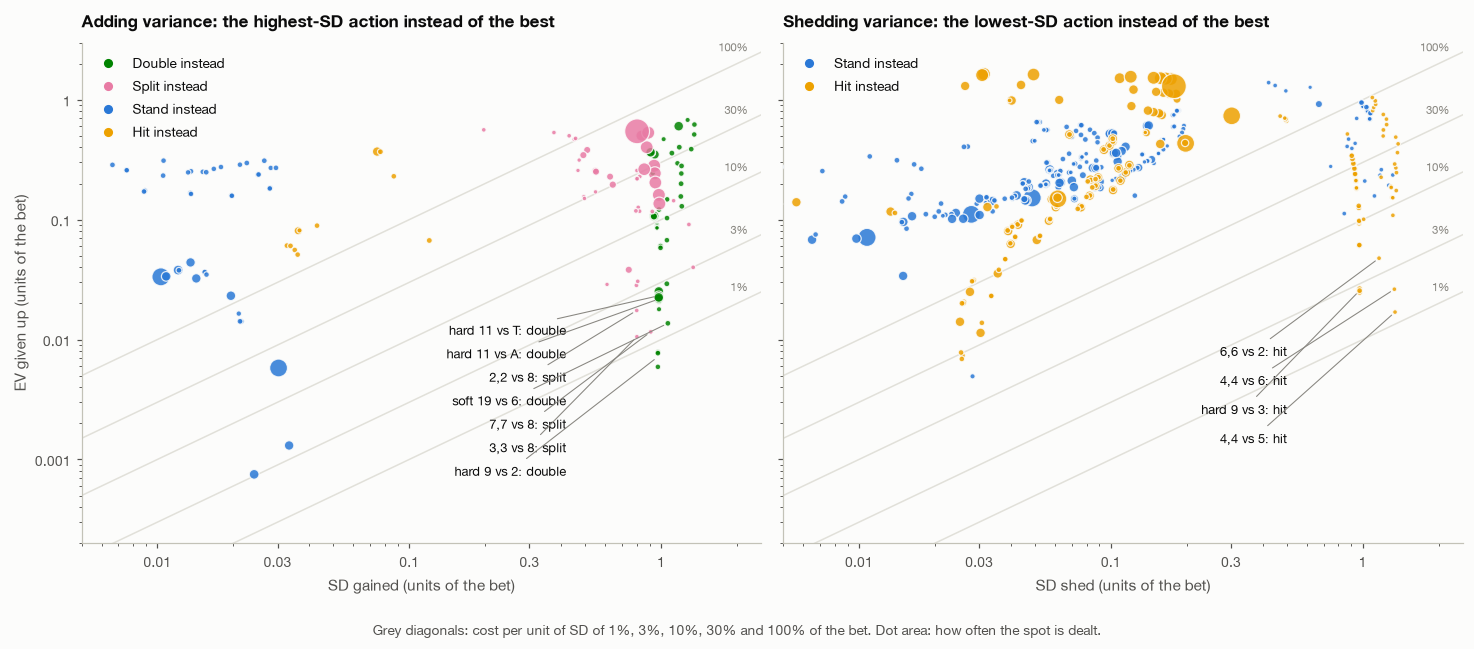

In [6]:
def label_column(ax, groups, n, x_text, y_top, y_bottom):
    # Labels for the n cheapest groups, stacked in an empty part of the panel with leader lines.
    top = groups.head(n).sort_values("cost", ascending=False)
    for (_, g), y in zip(top.iterrows(), np.geomspace(y_top, y_bottom, len(top))):
        ax.annotate(f"{g.situation}: {g.action.lower()}", xy=(g.dsd, g.cost), xytext=(x_text, y),
                    textcoords="data", fontsize=8.5, color=INK, ha="right", va="center",
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.7, shrinkA=2, shrinkB=3))


fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), sharey=True)
for ax, dev, groups, title, xlabel in (
        (axes[0], add, add_groups[add_groups.dsd >= 0.1], "Adding variance: the highest-SD action instead of the best",
         "SD gained (units of the bet)"),
        (axes[1], shed, shed_groups[shed_groups.dsd >= 0.1], "Shedding variance: the lowest-SD action instead of the best",
         "SD shed (units of the bet)")):
    for ratio in (0.01, 0.03, 0.1, 0.3, 1.0):
        xs = np.array([0.005, 3])
        ax.plot(xs, ratio * xs, color=GRID, lw=1, zorder=1)
        ax.text(2.2, ratio * 2.2 * 1.1, f"{ratio:.0%}", fontsize=7.5, color=MUTED, ha="right", va="bottom")
    handles = []
    for action in ("Double", "Split", "Stand", "Hit"):
        d = dev[dev.action == action]
        if len(d):
            color = COLOR[Action[action.upper()]]
            ax.scatter(d.dsd, d.cost.clip(lower=2e-4), s=6 + 9000 * d.freq, color=color,
                       alpha=0.85, edgecolor=SURFACE, linewidth=0.8, zorder=3)
            handles.append(Line2D([], [], marker="o", linestyle="none", markersize=7, markerfacecolor=color,
                                  markeredgecolor=SURFACE, label=f"{action} instead"))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.005, 2.5)
    ax.set_ylim(2e-4, 3)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=11)
    ax.legend(handles=handles, loc="upper left")
    for spine in ("left", "bottom"):
        ax.spines[spine].set_color(AXIS)
axes[0].set_ylabel("EV given up (units of the bet)")
label_column(axes[0], add_groups[add_groups.dsd >= 0.1], 7, 0.42, 0.012, 0.0008)
label_column(axes[1], shed_groups[shed_groups.dsd >= 0.1], 4, 0.5, 0.008, 0.0015)
for ax in axes:
    ax.set_xticks([0.01, 0.03, 0.1, 0.3, 1], ["0.01", "0.03", "0.1", "0.3", "1"])
axes[0].set_yticks([0.001, 0.01, 0.1, 1], ["0.001", "0.01", "0.1", "1"])
fig.text(0.5, -0.04, "Grey diagonals: cost per unit of SD of 1%, 3%, 10%, 30% and 100% of the bet. "
         "Dot area: how often the spot is dealt.", ha="center", fontsize=9, color=INK2)
plt.tight_layout()
plt.show()

**The rankings**, per chart cell (hands with the same total, best play and deviation are merged, weighted by how often each is dealt). Deviations that move the SD by less than 0.1 units are left out: they are not variance tools. *Dealt per 1,000 rounds* is how often the spot comes up; *EV cost per 1,000 rounds* is what always taking the deviation costs over 1,000 rounds, in units of the bet.

In [7]:
def ranking(groups, n, verb):
    top = groups[groups.dsd >= 0.1].head(n)
    return pd.DataFrame({
        "situation": top.situation, "hands": top.hands, "best play": top.best,
        "deviation": top.action, "EV given up": top.cost, f"SD {verb}": top.dsd,
        "cost per unit of SD": top.cost_per_sd, "dealt per 1,000 rounds": 1000 * top.freq,
        "EV cost per 1,000 rounds": 1000 * top.freq * top.cost,
    }).reset_index(drop=True)


FORMAT = {"EV given up": "{:.4f}", "SD gained": "{:.2f}", "SD shed": "{:.2f}", "cost per unit of SD": "{:.1%}",
          "dealt per 1,000 rounds": "{:.1f}", "EV cost per 1,000 rounds": "{:.3f}"}
add_rank = ranking(add_groups, 14, "gained")
shed_rank = ranking(shed_groups, 12, "shed")
for title, table in (("Cheapest ways to ADD variance", add_rank), ("Cheapest ways to SHED variance", shed_rank)):
    print(title)
    display(table.style.format({k: v for k, v in FORMAT.items() if k in table.columns}).hide(axis="index"))

Cheapest ways to ADD variance


situation,hands,best play,deviation,EV given up,SD gained,cost per unit of SD,"dealt per 1,000 rounds","EV cost per 1,000 rounds"
hard 9 vs 2,"7-2, 6-3, 5-4",Hit,Double,0.0072,0.97,0.7%,2.6,0.019
"7,7 vs 8",7-7,Hit,Split,0.0116,0.91,1.3%,0.4,0.005
soft 19 vs 6,8-A,Stand,Double,0.0137,1.06,1.3%,0.9,0.013
"3,3 vs 8",3-3,Hit,Split,0.0106,0.80,1.3%,0.4,0.004
"2,2 vs 8",2-2,Hit,Split,0.0175,0.80,2.2%,0.4,0.007
hard 11 vs A,"9-2, 8-3, 7-4, 6-5",Hit,Double,0.0218,0.98,2.2%,2.5,0.055
hard 11 vs T,"9-2, 8-3, 7-4, 6-5",Hit,Double,0.0232,0.98,2.4%,14.7,0.340
soft 19 vs 5,8-A,Stand,Double,0.0292,1.05,2.8%,1.0,0.029
"4,4 vs 4",4-4,Hit,Split,0.0400,1.34,3.0%,0.5,0.018
"6,6 vs 7",6-6,Hit,Split,0.0283,0.80,3.6%,0.5,0.013


Cheapest ways to SHED variance


situation,hands,best play,deviation,EV given up,SD shed,cost per unit of SD,"dealt per 1,000 rounds","EV cost per 1,000 rounds"
"4,4 vs 5",4-4,Split,Hit,0.0169,1.34,1.3%,0.4,0.007
"4,4 vs 6",4-4,Split,Hit,0.0263,1.34,2.0%,0.4,0.011
hard 9 vs 3,"7-2, 6-3, 5-4",Double,Hit,0.0256,0.97,2.6%,2.7,0.069
"6,6 vs 2",6-6,Split,Hit,0.0477,1.16,4.1%,0.5,0.022
hard 9 vs 4,"7-2, 6-3, 5-4",Double,Hit,0.0611,0.97,6.3%,2.7,0.167
"6,6 vs 3",6-6,Split,Hit,0.1086,1.32,8.2%,0.4,0.047
hard 9 vs 5,"7-2, 6-3, 5-4",Double,Hit,0.0956,0.97,9.9%,2.7,0.257
"8,8 vs 9",8-8,Split,Hit,0.1007,1.01,10.0%,0.4,0.043
"3,3 vs 5",3-3,Split,Hit,0.1523,1.32,11.6%,0.4,0.063
"2,2 vs 5",2-2,Split,Hit,0.1529,1.31,11.7%,0.5,0.070


**How much can play deviations move a whole round?** Each deviation only fires when its spot is dealt, so the per-decision numbers overstate what play can do for a round. The engine can value any fixed strategy exactly (`Solver(rules, strategy=...)`), so it is handed the chart plus a set of first-decision deviations and returns the round's exact EV and SD. Four sets: the cheap variance-adding deviations (cost ≤ 3% of the bet per unit of SD), the cheap variance-shedding ones (≤ 5%), and the two extremes, the highest-SD or lowest-SD action at every first decision. Each takes about 8 seconds.

In [8]:
def chart_with(deviations):
    # Basic strategy, except {(total, soft, pair, upcard): action} on the first decision of an unsplit hand.
    def strategy(view):
        if view.num_cards == 2 and not view.from_split:
            action = deviations.get((view.total, view.soft, view.pair, view.upcard))
            if action is not None and action in view.legal:
                return action
        return chart(view)
    return strategy


def deviation_set(groups, max_cost_per_sd=np.inf, min_dsd=0.0):
    chosen = {}
    keep = groups[(groups.cost_per_sd <= max_cost_per_sd) & (groups.dsd >= min_dsd)]
    for g in keep.sort_values("freq", ascending=False).itertuples():  # most common hands decide a shared cell
        key = (int(g.total), bool(g.soft), None if g.pair < 0 else int(g.pair), int(g.up))
        chosen.setdefault(key, Action[g.action.upper()])
    return chosen


PACKAGES = {
    "chart + cheap variance-adding deviations (≤ 3% per unit of SD)": deviation_set(add_groups, 0.03, 0.1),
    "chart + cheap variance-shedding deviations (≤ 5% per unit of SD)": deviation_set(shed_groups, 0.05, 0.1),
}
t0 = time.perf_counter()
package_values = {name: Solver(RULES, strategy=chart_with(devs)).round_value() for name, devs in PACKAGES.items()}
print(f"solved in {time.perf_counter() - t0:.0f} s")
def cell_text(key, action):
    total, soft, pair, up = key
    hand = f"{VALUE_NAMES[pair]},{VALUE_NAMES[pair]}" if pair is not None else f"{'soft' if soft else 'hard'} {total}"
    return f"{hand} vs {VALUE_NAMES[up]}: {NAME[action].lower()}"


for name, devs in PACKAGES.items():
    print(f"{name}, {len(devs)} cells:\n   " + "; ".join(cell_text(k, a) for k, a in devs.items()))

solved in 13 s
chart + cheap variance-adding deviations (≤ 3% per unit of SD), 9 cells:
   hard 11 vs T: double; hard 9 vs 2: double; hard 11 vs A: double; soft 19 vs 5: double; soft 19 vs 6: double; 4,4 vs 4: split; 7,7 vs 8: split; 3,3 vs 8: split; 2,2 vs 8: split
chart + cheap variance-shedding deviations (≤ 5% per unit of SD), 4 cells:
   hard 9 vs 3: hit; 6,6 vs 2: hit; 4,4 vs 5: hit; 4,4 vs 6: hit


In [9]:
EXTREMES = {
    "highest-SD action at every first decision": deviation_set(add_groups),
    "lowest-SD action at every first decision": deviation_set(shed_groups),
}
t0 = time.perf_counter()
package_values.update({name: Solver(RULES, strategy=chart_with(devs)).round_value() for name, devs in EXTREMES.items()})
print(f"solved in {time.perf_counter() - t0:.0f} s")

rows = [{"strategy": "basic strategy (chart)", "EV per round": chart_round.ev, "SD per round": chart_round.std}]
rows += [{"strategy": name, "EV per round": v.ev, "SD per round": v.std} for name, v in package_values.items()]
packages = pd.DataFrame(rows)
packages["EV change"] = packages["EV per round"] - chart_round.ev
packages["SD change"] = packages["SD per round"] - chart_round.std
# The same SD bought by scaling the bet instead (chart play, bet × SD ratio):
scale = packages["SD per round"] / chart_round.std
packages["EV change if the SD came from a bigger or smaller bet"] = (scale - 1) * chart_round.ev
packages.style.format({"EV per round": "{:+.3%}", "SD per round": "{:.3f}", "EV change": "{:+.3%}",
                       "SD change": "{:+.3f}", "EV change if the SD came from a bigger or smaller bet": "{:+.3%}"}
                      ).hide(axis="index")

solved in 13 s


strategy,EV per round,SD per round,EV change,SD change,EV change if the SD came from a bigger or smaller bet
basic strategy (chart),-0.476%,1.105,+0.000%,+0.000,-0.000%
chart + cheap variance-adding deviations (≤ 3% per unit of SD),-0.525%,1.135,-0.048%,+0.030,-0.013%
chart + cheap variance-shedding deviations (≤ 5% per unit of SD),-0.487%,1.099,-0.011%,-0.006,+0.003%
highest-SD action at every first decision,-7.357%,1.280,-6.881%,+0.175,-0.075%
lowest-SD action at every first decision,-37.349%,0.940,-36.873%,-0.165,+0.071%


**What to conclude.**

* **The cheapest variance-adding deviations** are doubling hard 9 against a 2 (under 1% of the bet per unit of SD), splitting 7,7 or 3,3 against an 8 and doubling soft 19 (A,8) against a 6 (about 1.3%), then splitting 2,2 vs 8 and doubling 11 against an ace or a ten (2–2.5%). Doubling 11 vs T is by far the most common of these, at about 15 hands per 1,000 rounds.
* **The cheapest variance-shedding deviations** are declining a marginal split or double: hit 4,4 against a 5 or 6 instead of splitting (1.3–2%), hit hard 9 against a 3 instead of doubling (2.6%), hit 6,6 against a 2 (4%). After those the price climbs quickly, to 6–13% for the next eight.
* **"Lowest SD" is not "safest".** The lowest-SD action at every decision costs over a third of a bet per round: it hits hands like hard 20, because a near-certain bust is a low-variance outcome. A leader wants to avoid *losing*, not to reduce SD at any price.
* **Play moves a round only slightly.** All the cheap variance-adding deviations together raise the round's SD by about 0.03 units (1.105 → 1.135) for about 0.05% of the bet; the same extra SD from a 2.7% bigger bet would cost about 0.013%. The cheap shedding set lowers the SD by only 0.006. **Bet size is the main variance dial**; play deviations are fine-tuning once the bet is down (and, in a match, a way to diverge from an opponent who plays the chart, since the dealer's draws change with every card taken).

## 3. One round, and a 5-round match at flat bets

`Solver(rules, strategy=chart).round_value().dist` is the exact distribution of one round of chart play before the deal (no insurance, no side bets).

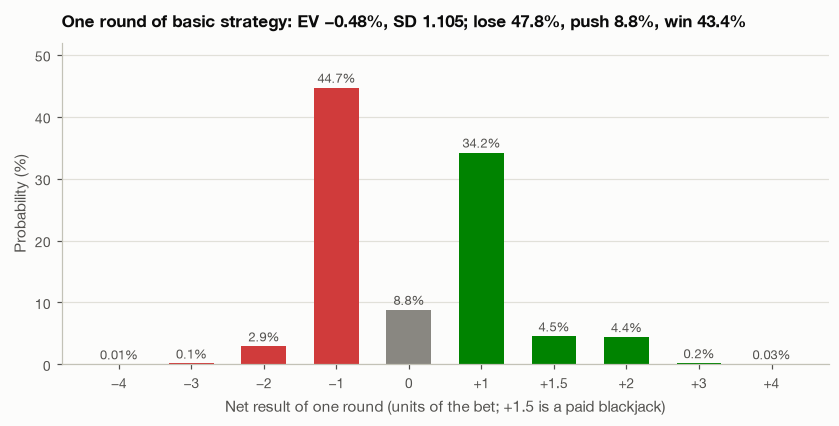

In [10]:
support = sorted(chart_round.dist)
probs = np.array([chart_round.dist[x] for x in support])
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [CRITICAL if x < 0 else (MUTED if x == 0 else GREEN) for x in support]
ax.bar(range(len(support)), 100 * probs, color=colors, width=0.62)
for i, p in enumerate(probs):
    ax.text(i, 100 * p + 0.8, f"{100 * p:.1f}%" if p >= 0.001 else f"{100 * p:.2f}%", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(range(len(support)), [minus(f"{x:+g}") if x else "0" for x in support])
ax.set_xlabel("Net result of one round (units of the bet; +1.5 is a paid blackjack)")
ax.set_ylabel("Probability (%)")
ax.set_ylim(0, 52)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
p_lose = probs[np.array(support) < 0].sum()
p_win = probs[np.array(support) > 0].sum()
ax.set_title(minus(f"One round of basic strategy: EV {chart_round.ev:+.2%}, SD {chart_round.std:.3f}; "
                   f"lose {p_lose:.1%}, push {chart_round.dist[0.0]:.1%}, win {p_win:.1%}"), fontsize=11)
plt.show()

A round is lopsided: you lose more often (47.8%) than you win (43.4%), and the gap is paid back by blackjacks (+1.5) and doubles (+2). Over a match the question is what flat betting does to the **final balance**. A flat bettor is a tiny `Agent` subclass that overrides `bet()` (it bets everything left if the balance falls below its stake) and otherwise plays the chart. 50,000 matches are played with `play_player` on the seeded shoes of `match_shoes(seed)`, the **same shoes for every bet size**, so the bet sizes can be compared match by match. This takes about 20 seconds.

In [11]:
class FlatBettor(Agent):
    # Bets the same amount every round (or all that is left, if less); plays basic strategy.
    def __init__(self, amount):
        super().__init__()
        self.amount = amount
        self.name = f"flat {amount}"

    def bet(self, state):
        return state.clamp_bet(self.amount)


BETS = [10, 100, 250, 500]
N_MATCHES = 50_000
final = {b: np.empty(N_MATCHES) for b in BETS}
bankrupt = {b: np.zeros(N_MATCHES, dtype=bool) for b in BETS}
bettors = {b: FlatBettor(b) for b in BETS}
t0 = time.perf_counter()
for seed in range(N_MATCHES):
    shoes = match_shoes(seed, RULES)
    for b, agent in bettors.items():
        played = play_player(agent, shoes, random.Random(seed), RULES)
        final[b][seed] = played.final_balance
        bankrupt[b][seed] = played.bankrupt
print(f"{N_MATCHES:,} matches × {len(BETS)} bet sizes in {time.perf_counter() - t0:.0f} s")

# Exact check for the flat-10 bettor: chips are never short, so its 5 rounds are independent copies of one round.
five = {0.0: 1.0}
for _ in range(RULES.num_rounds):
    nxt = {}
    for s, p in five.items():
        for x, q in chart_round.dist.items():
            nxt[s + x] = nxt.get(s + x, 0.0) + p * q
    five = nxt
exact10 = {RULES.starting_chips + 10 * s: p for s, p in five.items()}
sim10 = pd.Series(final[10]).value_counts(normalize=True)
z = [(sim10.get(v, 0.0) - p) / np.sqrt(p * (1 - p) / N_MATCHES) for v, p in exact10.items() if p > 1e-4]
print(f"flat 10: simulated vs exact final-balance probabilities at {len(z)} values: "
      f"largest difference {max(abs(x) for x in z):.1f} standard errors")

50,000 matches × 4 bet sizes in 19 s
flat 10: simulated vs exact final-balance probabilities at 30 values: largest difference 1.9 standard errors


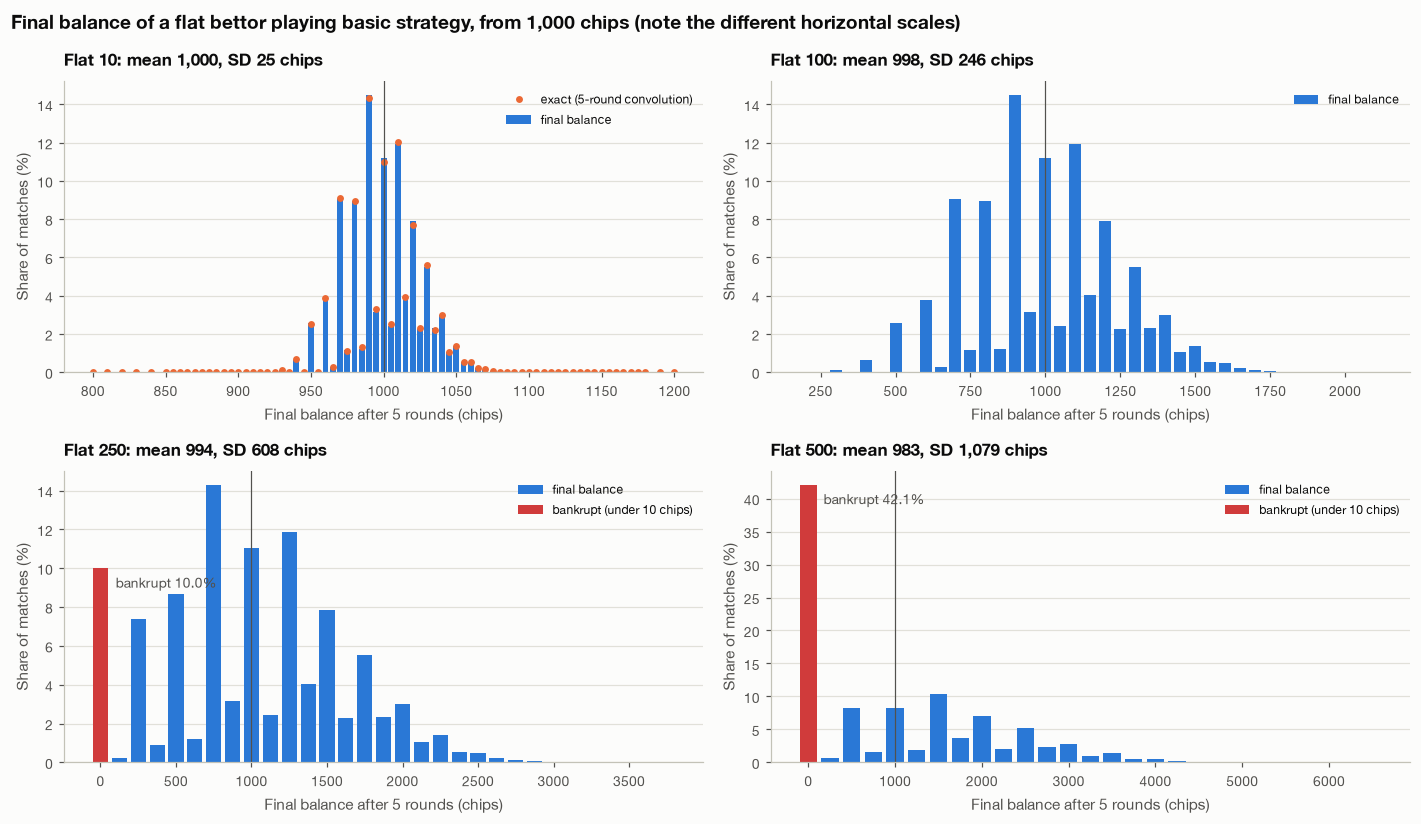

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
for ax, b in zip(axes.flat, BETS):
    vals, counts_ = np.unique(final[b], return_counts=True)
    p = counts_ / N_MATCHES
    width = 0.8 * (b / 2)
    is_bust = vals < RULES.min_bet
    ax.bar(vals[~is_bust], 100 * p[~is_bust], width=width, color=BLUE, label="final balance")
    if is_bust.any():
        ax.bar(vals[is_bust], 100 * p[is_bust], width=width, color=CRITICAL, label="bankrupt (under 10 chips)")
        ax.annotate(f"bankrupt {bankrupt[b].mean():.1%}", (vals[is_bust][0], 100 * p[is_bust].sum()),
                    xytext=(10, -4), textcoords="offset points", fontsize=9, color=INK2, va="top")
    if b == 10:
        xs = np.array(sorted(exact10))
        ax.plot(xs, [100 * exact10[x] for x in xs], linestyle="none", marker="o", markersize=3.5,
                color=ORANGE, label="exact (5-round convolution)")
    ax.axvline(RULES.starting_chips, color=INK2, lw=0.8)
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_title(f"Flat {b}: mean {final[b].mean():,.0f}, SD {final[b].std():,.0f} chips", fontsize=11)
    ax.set_xlabel("Final balance after 5 rounds (chips)")
    ax.set_ylabel("Share of matches (%)")
    ax.legend(loc="upper right", fontsize=8)
fig.suptitle("Final balance of a flat bettor playing basic strategy, from 1,000 chips (note the different horizontal scales)",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout()
plt.show()

In [13]:
def score_vs(a, b):
    # P(win) + 5/9 P(tie) of balance array a against b, match by match.
    return (a > b).mean() + RULES.tie_value * (a == b).mean()


summary = pd.DataFrame({
    b: {"mean final balance": final[b].mean(), "SD of final balance": final[b].std(),
        "5th percentile": np.percentile(final[b], 5), "median": np.median(final[b]),
        "95th percentile": np.percentile(final[b], 95),
        "P(bankrupt)": bankrupt[b].mean(), "P(finish below 1,000)": (final[b] < 1000).mean(),
        "P(finish on 1,000)": (final[b] == 1000).mean(), "P(finish above 1,000)": (final[b] > 1000).mean(),
        "P(beat a flat-10 player on the same cards)": (final[b] > final[10]).mean(),
        "P(tie with them)": (final[b] == final[10]).mean(),
        "score vs flat-10: P(win) + 5/9 P(tie)": score_vs(final[b], final[10])}
    for b in BETS}).T
summary.index.name = "flat bet"
chip_cols = ["mean final balance", "SD of final balance", "5th percentile", "median", "95th percentile"]
summary.style.format("{:,.0f}", subset=chip_cols).format("{:.1%}", subset=[c for c in summary.columns if c not in chip_cols]
                                                         ).format("{:.3f}", subset=["score vs flat-10: P(win) + 5/9 P(tie)"])

,mean final balance,SD of final balance,5th percentile,median,95th percentile,P(bankrupt),"P(finish below 1,000)","P(finish on 1,000)","P(finish above 1,000)",P(beat a flat-10 player on the same cards),P(tie with them),score vs flat-10: P(win) + 5/9 P(tie)
flat bet,,,,,,,,,,,,
10,"1,000",25,960,"1,000","1,040",0.0%,45.6%,11.2%,43.3%,0.0%,100.0%,0.556
100,998,246,600,"1,000","1,400",0.0%,45.6%,11.2%,43.3%,43.3%,11.2%,0.495
250,994,608,0,"1,000","2,000",10.0%,45.8%,11.1%,43.1%,43.2%,11.0%,0.493
500,983,"1,079",0,500,"3,000",42.1%,52.7%,8.2%,39.1%,39.3%,7.4%,0.434


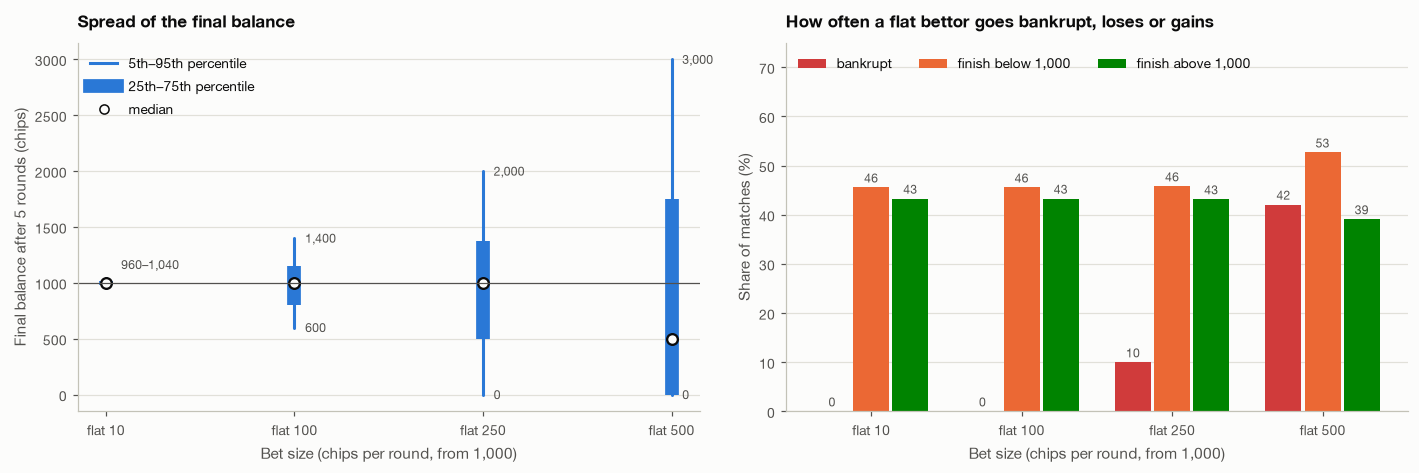

In [14]:
fig, (ax, az) = plt.subplots(1, 2, figsize=(13, 4.4))
xs = np.arange(len(BETS))
for x, b in zip(xs, BETS):
    p5, p25, p50, p75, p95 = np.percentile(final[b], [5, 25, 50, 75, 95])
    ax.plot([x, x], [p5, p95], color=BLUE, lw=2, solid_capstyle="round")
    ax.plot([x, x], [p25, p75], color=BLUE, lw=9, solid_capstyle="butt")
    ax.plot(x, p50, marker="o", markersize=7, color=SURFACE, markeredgecolor=INK, markeredgewidth=1.5)
    if p95 - p5 > 300:
        ax.annotate(f"{p95:,.0f}", (x, p95), xytext=(7, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
        ax.annotate(f"{p5:,.0f}", (x, p5), xytext=(7, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
    else:
        ax.annotate(f"{p5:,.0f}–{p95:,.0f}", (x, p50), xytext=(10, 12), textcoords="offset points", fontsize=8,
                    color=INK2, va="center")
ax.axhline(RULES.starting_chips, color=INK2, lw=0.8)
ax.set_xticks(xs, [f"flat {b}" for b in BETS])
ax.set_ylabel("Final balance after 5 rounds (chips)")
ax.set_xlabel("Bet size (chips per round, from 1,000)")
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_title("Spread of the final balance", fontsize=11)
ax.legend(handles=[Line2D([], [], color=BLUE, lw=2, label="5th–95th percentile"),
                   Line2D([], [], color=BLUE, lw=9, label="25th–75th percentile"),
                   Line2D([], [], marker="o", color=SURFACE, markeredgecolor=INK, linestyle="none", label="median")],
          loc="upper left")

width = 0.26
for i, (label, values, color) in enumerate((
        ("bankrupt", [bankrupt[b].mean() for b in BETS], CRITICAL),
        ("finish below 1,000", [(final[b] < 1000).mean() for b in BETS], ORANGE),
        ("finish above 1,000", [(final[b] > 1000).mean() for b in BETS], GREEN))):
    az.bar(xs + (i - 1) * width, 100 * np.array(values), width=width * 0.92, color=color, label=label)
    for x, v in zip(xs, values):
        az.text(x + (i - 1) * width, 100 * v + 1, f"{100 * v:.0f}", ha="center", fontsize=8, color=INK2)
az.set_xticks(xs, [f"flat {b}" for b in BETS])
az.set_ylabel("Share of matches (%)")
az.set_xlabel("Bet size (chips per round, from 1,000)")
az.set_ylim(0, 75)
az.yaxis.grid(True)
az.set_axisbelow(True)
az.legend(loc="upper left", ncol=3)
az.set_title("How often a flat bettor goes bankrupt, loses or gains", fontsize=11)
plt.tight_layout()
plt.show()

**What to conclude.**

* The **SD of the final balance grows almost in proportion to the bet**: about 25 chips at flat 10, 250 at flat 100, 610 at flat 250 and 1,080 at flat 500. At the larger bets it falls a little short of proportional because a bankrupt player stops losing. Bankruptcy is the price: 1 match in 10 at flat 250 and more than 4 in 10 at flat 500, where two net losses end the match.
* **Big flat bets do not buy a better typical result.** Up to flat 250 the median finish is 1,000 and only 43% of matches end above it (a round is lost more often than won); at flat 500 the median is 500 and 39% end above 1,000.
* **Against an opponent who bets 10 and plays the same chart on the same cards**, a flat-100 player wins exactly when the shared 5-round result is positive. That happens in about 43% of matches and ties in about 11%, a score of about 0.495 (0.434 at flat 500), below the 0.556 (5/9) that copying the opponent would guarantee. Raising the bet alone, with the same plays on the same cards, is a bet on the *shared* outcome and loses to the tie value; separation has to come from playing or side-betting differently, or from choosing *when* to bet big.
* All-in betting has a further hidden cost, quantified in section 4: with no chips left, doubles and splits are not allowed.

## 4. Side bets as variance tools

Both side bets settle on the first four cards, before you play, and side bets have no cap besides the balance (a 600-chip side bet next to a 10-chip main bet is accepted in the app). Two ways to get their odds, both calling only engine functions:

* **exact enumeration:** every pair of player cards in a fresh 6-deck shoe is equally likely, and so is every pair of dealer cards from what is left; each is scored with `perfect_pairs_payout` or `four_card_total` + `four_card_total_payout` from `rivals.side_bets`. For 4-Card Total the player pairs are grouped by rank (suits cannot affect a total), and all 47,895 dealer pairs are enumerated for one representative of each of the 91 groups;
* **simulation:** the 600,000 seeded rounds of section 2, which played both side bets through `play_round`.

In [15]:
def perfect_pairs_odds(rules):
    deck = fresh_decks(rules.num_decks).tolist()
    tally = Counter(perfect_pairs_payout(a, b, rules) for a, b in combinations(deck, 2))
    n = sum(tally.values())
    return {payout: k / n for payout, k in sorted(tally.items())}


def four_card_total_odds(rules):
    deck = fresh_decks(rules.num_decks).tolist()
    groups, example = Counter(), {}
    for i, j in combinations(range(len(deck)), 2):
        key = tuple(sorted((RANK[deck[i]], RANK[deck[j]])))
        groups[key] += 1
        example.setdefault(key, (i, j))
    n_pairs = sum(groups.values())
    odds = Counter()
    for key, n_player in groups.items():
        i, j = example[key]
        rest = [c for k, c in enumerate(deck) if k not in (i, j)]
        tally = Counter(four_card_total_payout(four_card_total(deck[i], deck[j], c, d), rules)
                        for c, d in combinations(rest, 2))
        n_dealer = sum(tally.values())
        for payout, k in tally.items():
            odds[payout] += (n_player / n_pairs) * (k / n_dealer)
    return dict(sorted(odds.items()))


def moments(odds):
    # EV and SD per chip staked; a payout of 0 means the stake is lost.
    nets = {(p if p else -1.0): q for p, q in odds.items()}
    ev = sum(x * q for x, q in nets.items())
    return ev, sum((x - ev) ** 2 * q for x, q in nets.items()) ** 0.5


t0 = time.perf_counter()
pp_odds, fct_odds = perfect_pairs_odds(RULES), four_card_total_odds(RULES)
print(f"exact enumeration in {time.perf_counter() - t0:.1f} s")

TIERS = {"Perfect Pairs": [("perfect pair (same suit), 25:1", 25), ("coloured pair, 12:1", 12),
                           ("mixed pair, 6:1", 6), ("no pair: stake lost", 0)],
         "4-Card Total": [("40 or more, 10:1", 10), ("38–39, 8:1", 8), ("36–37, 2:1", 2), ("35 or less: stake lost", 0)]}
sims = {"Perfect Pairs": pp_net, "4-Card Total": fct_net}
exact_odds = {"Perfect Pairs": pp_odds, "4-Card Total": fct_odds}
rows = []
for bet_name, tiers in TIERS.items():
    sim = sims[bet_name]
    for tier, payout in tiers:
        p_exact = exact_odds[bet_name].get(payout, 0.0)
        p_sim = (sim == (payout if payout else -1)).mean()
        rows.append({"side bet": bet_name, "result": tier, "exact": p_exact, "simulated": p_sim,
                     "simulated ± (95%)": 1.96 * np.sqrt(p_sim * (1 - p_sim) / N_ROUNDS)})
    ev, sd = moments(exact_odds[bet_name])
    rows.append({"side bet": bet_name, "result": "EV per chip staked", "exact": ev, "simulated": sim.mean(),
                 "simulated ± (95%)": 1.96 * sim.std() / np.sqrt(N_ROUNDS)})
    rows.append({"side bet": bet_name, "result": "SD per chip staked", "exact": sd, "simulated": sim.std(),
                 "simulated ± (95%)": np.nan})
side_table = pd.DataFrame(rows).set_index(["side bet", "result"])


def side_cell(result, column, v):
    if pd.isna(v):
        return ""
    if result == "SD per chip staked":
        return f"{v:.3f}"
    if result == "EV per chip staked":
        return f"{v:.2%}" if column == "simulated ± (95%)" else minus(f"{v:+.2%}")
    return f"{v:.3%}"


side_display = pd.DataFrame({col: [side_cell(idx[1], col, side_table.loc[idx, col]) for idx in side_table.index]
                             for col in side_table.columns}, index=side_table.index)
side_display

exact enumeration in 1.1 s


exact simulated simulated ± (95%)
side bet      result                                                             
Perfect Pairs perfect pair (same suit), 25:1   1.608%    1.631%            0.032%
              coloured pair, 12:1              1.929%    1.906%            0.035%
              mixed pair, 6:1                  3.859%    3.872%            0.049%
              no pair: stake lost             92.605%   92.591%            0.066%
              EV per chip staked               −6.11%    −5.70%             0.99%
              SD per chip staked                3.891     3.906                  
4-Card Total  40 or more, 10:1                 3.185%    3.170%            0.044%
              38–39, 8:1                       4.427%    4.408%            0.052%
              36–37, 2:1                       6.879%    6.877%            0.064%
              35 or less: stake lost          85.510%   85.546%            0.089%
              EV per chip staked               −4.49%    −4.83%             0.68%
              SD per chip staked                2.673     2.668

**Price of variance, tool by tool.** For each tool, the EV it costs per unit of SD of its own outcome, with both measured per chip staked (for a play deviation, per unit of the bet in the spot where it is used). The main bet appears twice: with chips to spare, and **all-in**, where no chips are left to double or split; the engine values the all-in case exactly by solving the rules with doubling and splitting switched off. Correlations from the simulation show how far the side bets move with the main bet.

all-in round solved in 2 s: house edge 2.34%, SD 0.985
correlation with the main bet's result: Perfect Pairs +0.037, 4-Card Total +0.038


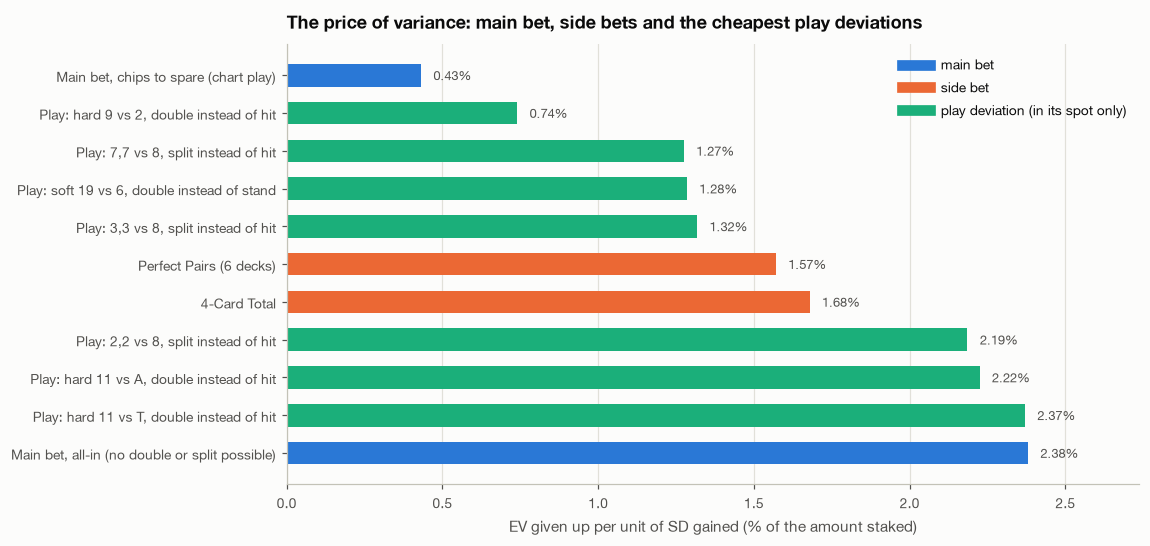

tool,EV cost per chip,SD per chip,EV cost per unit of SD
"Main bet, chips to spare (chart play)",0.476%,1.105,0.43%
"Play: hard 9 vs 2, double instead of hit",0.718%,0.971,0.74%
"Play: 7,7 vs 8, split instead of hit",1.159%,0.909,1.27%
"Play: soft 19 vs 6, double instead of stand",1.366%,1.063,1.28%
"Play: 3,3 vs 8, split instead of hit",1.055%,0.801,1.32%
Perfect Pairs (6 decks),6.109%,3.891,1.57%
4-Card Total,4.487%,2.673,1.68%
"Play: 2,2 vs 8, split instead of hit",1.748%,0.800,2.19%
"Play: hard 11 vs A, double instead of hit",2.182%,0.981,2.22%
"Play: hard 11 vs T, double instead of hit",2.319%,0.978,2.37%


In [16]:
t0 = time.perf_counter()
all_in = solver_for(RULES.with_(double_totals=(), max_splits=0)).round_value()
print(f"all-in round solved in {time.perf_counter() - t0:.0f} s: house edge {all_in.house_edge:.2%}, SD {all_in.std:.3f}")
print(f"correlation with the main bet's result: Perfect Pairs {np.corrcoef(main_net, pp_net)[0, 1]:+.3f}, "
      f"4-Card Total {np.corrcoef(main_net, fct_net)[0, 1]:+.3f}")

pp_ev, pp_sd = moments(pp_odds)
fct_ev, fct_sd = moments(fct_odds)
tools = [("Main bet, chips to spare (chart play)", -chart_round.ev, chart_round.std, "main"),
         ("Main bet, all-in (no double or split possible)", all_in.house_edge, all_in.std, "main"),
         ("4-Card Total", -fct_ev, fct_sd, "side"), ("Perfect Pairs (6 decks)", -pp_ev, pp_sd, "side")]
for _, g in add_rank.head(7).iterrows():
    tools.append((f"Play: {g.situation}, {g.deviation.lower()} instead of {g['best play'].lower()}",
                  g["EV given up"], g["SD gained"], "play"))
price = pd.DataFrame(tools, columns=["tool", "EV cost per chip", "SD per chip", "kind"])
price["EV cost per unit of SD"] = price["EV cost per chip"] / price["SD per chip"]
price = price.sort_values("EV cost per unit of SD").reset_index(drop=True)

KIND_COLOR = {"main": BLUE, "side": ORANGE, "play": AQUA}
fig, ax = plt.subplots(figsize=(10, 5.2))
ys = np.arange(len(price))[::-1]
ax.barh(ys, 100 * price["EV cost per unit of SD"], color=[KIND_COLOR[k] for k in price.kind], height=0.6)
for y, v in zip(ys, price["EV cost per unit of SD"]):
    ax.text(100 * v + 0.04, y, f"{v:.2%}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(ys, price.tool)
ax.set_xlabel("EV given up per unit of SD gained (% of the amount staked)")
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_xlim(0, 100 * price["EV cost per unit of SD"].max() * 1.15)
ax.set_title("The price of variance: main bet, side bets and the cheapest play deviations")
ax.legend(handles=[Line2D([], [], color=c, lw=7, label=l) for l, c in
                   (("main bet", BLUE), ("side bet", ORANGE), ("play deviation (in its spot only)", AQUA))],
          loc="upper right")
plt.show()
price.drop(columns="kind").style.format({"EV cost per chip": "{:.3%}", "SD per chip": "{:.3f}",
                                         "EV cost per unit of SD": "{:.2%}"}).hide(axis="index")

Those prices treat each tool on its own. What a player actually controls is **one round's total result**: what happens to its EV and SD (per unit of main bet, chart play) as you (a) scale the main bet, (b) add a side-bet stake *k* × the main bet, or (c) use the deviation sets from section 2? Side-bet results are almost independent of the main bet, so their SDs add in quadrature: small side bets add little SD for their cost, and only large stakes approach the standalone price.

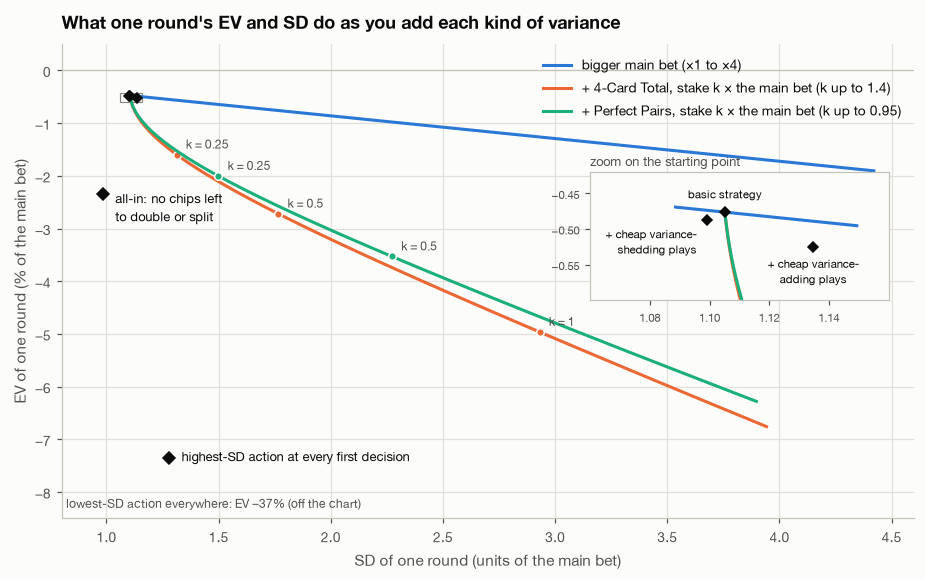

In [17]:
sigma, ev0 = chart_round.std, chart_round.ev
fig, ax = plt.subplots(figsize=(10, 5.6))
m = np.linspace(1, 4, 50)
ax.plot(m * sigma, 100 * m * ev0, color=BLUE, lw=2, label="bigger main bet (×1 to ×4)")
for name, ev_s, sd_s, side, color in (("4-Card Total", fct_ev, fct_sd, fct_net, ORANGE),
                                      ("Perfect Pairs", pp_ev, pp_sd, pp_net, AQUA)):
    cov = np.corrcoef(main_net, side)[0, 1] * sigma * sd_s  # exact SDs, correlation from the simulation
    k = np.linspace(0, 1.4 if name == "4-Card Total" else 0.95, 60)
    sd = np.sqrt(sigma ** 2 + (k * sd_s) ** 2 + 2 * k * cov)
    ax.plot(sd, 100 * (ev0 + k * ev_s), color=color, lw=2, label=f"+ {name}, stake k × the main bet (k up to {k[-1]:g})")
    for kk in (0.25, 0.5, 1.0):
        if kk <= k[-1]:
            s = np.sqrt(sigma ** 2 + (kk * sd_s) ** 2 + 2 * kk * cov)
            ax.plot(s, 100 * (ev0 + kk * ev_s), marker="o", markersize=5, color=color, markeredgecolor=SURFACE)
            ax.annotate(f"k = {kk:g}", (s, 100 * (ev0 + kk * ev_s)), xytext=(6, 4), textcoords="offset points",
                        fontsize=8, color=INK2)
cluster = {"basic strategy": chart_round,
           "+ cheap variance-adding plays": package_values[list(PACKAGES)[0]],
           "+ cheap variance-shedding plays": package_values[list(PACKAGES)[1]]}
for v in cluster.values():
    ax.plot(v.std, 100 * v.ev, marker="D", markersize=5, color=INK, linestyle="none", zorder=4)
for label, v, offset in (("all-in: no chips left\nto double or split", all_in, (8, -10)),
                         ("highest-SD action at every first decision", package_values[list(EXTREMES)[0]], (8, 0))):
    ax.plot(v.std, 100 * v.ev, marker="D", markersize=6, color=INK, linestyle="none", zorder=4)
    ax.annotate(label, (v.std, 100 * v.ev), xytext=offset, textcoords="offset points", fontsize=8.5, color=INK,
                va="center", linespacing=1.2)
ax.annotate("lowest-SD action everywhere: EV " + minus(f"{100 * package_values[list(EXTREMES)[1]].ev:.0f}%") + " (off the chart)",
            (0.82, -8.3), fontsize=8, color=INK2)

# Zoom on the starting point: the deviation sets barely move the round.
inset = ax.inset_axes([0.62, 0.46, 0.35, 0.27])
mm = np.linspace(0.985, 1.04, 20)
inset.plot(mm * sigma, 100 * mm * ev0, color=BLUE, lw=2)
for ev_s, sd_s, side, color in ((fct_ev, fct_sd, fct_net, ORANGE), (pp_ev, pp_sd, pp_net, AQUA)):
    kk = np.linspace(0, 0.03, 30)
    cov = np.corrcoef(main_net, side)[0, 1] * sigma * sd_s
    inset.plot(np.sqrt(sigma ** 2 + (kk * sd_s) ** 2 + 2 * kk * cov), 100 * (ev0 + kk * ev_s), color=color, lw=2)
placement = {"basic strategy": ("basic strategy", (0, 11), "center"),
             "+ cheap variance-adding plays": ("+ cheap variance-\nadding plays", (0, -17), "center"),
             "+ cheap variance-shedding plays": ("+ cheap variance-\nshedding plays", (-7, -15), "right")}
for name, v in cluster.items():
    text, offset, ha = placement[name]
    inset.plot(v.std, 100 * v.ev, marker="D", markersize=5, color=INK, linestyle="none", zorder=4)
    inset.annotate(text, (v.std, 100 * v.ev), xytext=offset, textcoords="offset points", fontsize=7.5,
                   color=INK, ha=ha, va="center", linespacing=1.15)
inset.set_xlim(1.06, 1.16)
inset.set_ylim(-0.6, -0.42)
inset.set_xticks([1.08, 1.10, 1.12, 1.14])
inset.set_yticks([-0.55, -0.50, -0.45])
inset.set_title("zoom on the starting point", fontsize=8.5, fontweight="normal", color=INK2, pad=4)
inset.tick_params(labelsize=7.5)
inset.set_facecolor(SURFACE)
for spine in inset.spines.values():
    spine.set_visible(True)
    spine.set_color(AXIS)
ax.add_patch(plt.Rectangle((1.06, -0.6), 0.1, 0.18, fill=False, edgecolor=MUTED, lw=0.8))
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xlabel("SD of one round (units of the main bet)")
ax.set_ylabel("EV of one round (% of the main bet)")
ax.set_xlim(0.8, 4.6)
ax.set_ylim(-8.5, 0.5)
ax.yaxis.grid(True)
ax.xaxis.grid(True)
ax.set_axisbelow(True)
ax.set_title("What one round's EV and SD do as you add each kind of variance")
ax.legend(loc="upper right")
plt.show()

SD is only half of a variance tool; the other half is the **shape**: how big a multiple of the stake can come back. For a player far behind late in a match, the chance of a large multiple is what matters.

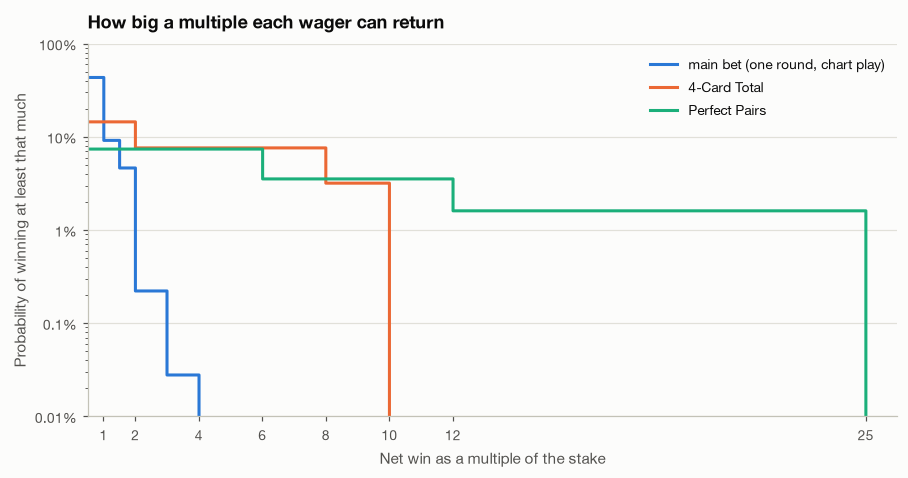

,"main bet (one round, chart play)",4-Card Total,Perfect Pairs
net ≥ 1× stake,43.39%,14.49%,7.40%
net ≥ 1.5× stake,9.17%,14.49%,7.40%
net ≥ 2× stake,4.64%,14.49%,7.40%
net ≥ 3× stake,0.22%,7.61%,7.40%
net ≥ 4× stake,0.03%,7.61%,7.40%
net ≥ 6× stake,0.00%,7.61%,7.40%
net ≥ 8× stake,0.00%,7.61%,3.54%
net ≥ 10× stake,0.00%,3.19%,3.54%
net ≥ 12× stake,0.00%,0.00%,3.54%
net ≥ 25× stake,0.00%,0.00%,1.61%


In [18]:
multiples = np.array([1, 1.5, 2, 3, 4, 6, 8, 10, 12, 25])
main_odds = chart_round.dist
pp_nets = {(p if p else -1.0): q for p, q in pp_odds.items()}
fct_nets = {(p if p else -1.0): q for p, q in fct_odds.items()}
survival = pd.DataFrame({
    "main bet (one round, chart play)": [sum(q for x, q in main_odds.items() if x >= mlt) for mlt in multiples],
    "4-Card Total": [sum(q for x, q in fct_nets.items() if x >= mlt) for mlt in multiples],
    "Perfect Pairs": [sum(q for x, q in pp_nets.items() if x >= mlt) for mlt in multiples],
}, index=[f"net ≥ {mlt:g}× stake" for mlt in multiples])

fig, ax = plt.subplots(figsize=(9.5, 4.4))
grid_m = np.linspace(0.5, 26, 2000)
for (name, nets), color in zip((("main bet (one round, chart play)", main_odds), ("4-Card Total", fct_nets),
                                ("Perfect Pairs", pp_nets)), (BLUE, ORANGE, AQUA)):
    curve = [100 * sum(q for x, q in nets.items() if x >= g) for g in grid_m]
    ax.step(grid_m, np.maximum(curve, 1e-3), where="post", color=color, lw=2, label=name)
ax.set_yscale("log")
ax.set_ylim(0.01, 100)
ax.set_xlim(0.5, 26)
ax.set_yticks([0.01, 0.1, 1, 10, 100], ["0.01%", "0.1%", "1%", "10%", "100%"])
ax.set_xticks([1, 2, 4, 6, 8, 10, 12, 25])
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("Net win as a multiple of the stake")
ax.set_ylabel("Probability of winning at least that much")
ax.set_title("How big a multiple each wager can return")
ax.legend(loc="upper right")
plt.show()
survival.style.format("{:.2%}")

**Deck count matters for side bets.** The main-bet chart barely depends on the number of decks (notebook 01), but the side bets do, Perfect Pairs most of all: a perfect pair (same rank and suit) is impossible with one deck. Exact enumeration at 1, 2, 6 and 8 decks:

In [19]:
t0 = time.perf_counter()
rows = []
for decks in (1, 2, 6, 8):
    r = RULES.with_(num_decks=decks)
    for name, odds in (("Perfect Pairs", perfect_pairs_odds(r)), ("4-Card Total", four_card_total_odds(r))):
        ev, sd = moments(odds)
        rows.append({"decks": decks, "side bet": name, "EV per chip": ev, "SD per chip": sd,
                     "EV cost per unit of SD": -ev / sd, "P(any win)": 1 - odds.get(0, 0.0)})
print(f"enumerated in {time.perf_counter() - t0:.0f} s")
deck_side = pd.DataFrame(rows).pivot(index="decks", columns="side bet")
deck_side.style.format(lambda v: minus(f"{v:+.2%}"), subset=["EV per chip"]).format(
    "{:.3f}", subset=["SD per chip"]).format("{:.2%}", subset=["EV cost per unit of SD", "P(any win)"])

enumerated in 3 s


**What to conclude.**

* **At 6 decks the two side bets cost about the same per unit of SD**: 4-Card Total gives up 4.49% of the stake for an SD of 2.67 per chip (1.68% per unit of SD), Perfect Pairs 6.11% for an SD of 3.89 (1.57%). That is about **4× the main bet's 0.43%**, and in the same range as the play deviations: the four cheapest plays (double 9 vs 2, split 7,7 or 3,3 vs 8, double soft 19 vs 6, at 0.7–1.3%) are cheaper, and doubling 11 vs A or T (2.2–2.4%) is dearer.
* **But side bets scale and play deviations do not.** A deviation only applies in its spot and buys at most about one unit of SD there; all the cheap ones together add 0.03 to a round's SD. A side bet can be as large as the balance. Small side bets are poor value, though: being nearly independent of the main bet (correlation about +0.04), a stake of a quarter of the main bet adds little SD while costing its full EV; the price approaches the standalone figure only once the side bet dominates the round.
* **Only side bets can multiply a stake quickly.** One main-bet round wins 2× or more 4.6% of the time and 4× or more 0.03% of the time. 4-Card Total wins 8× or more 7.6% of the time and 10× 3.2%; Perfect Pairs wins 12× or more 3.5% of the time and 25× 1.6%. A player who needs a large comeback late in a match has no other tool for it.
* **All-in on the main bet is a poor way to buy variance:** with no chips left to double or split, the house edge jumps from 0.48% to 2.34% and the SD falls from 1.105 to 0.985, about 2.4% of the stake per unit of SD, worse than either side bet.
* **Perfect Pairs depends heavily on the deck count:** −6.1% at 6 decks, −22% at 2, −47% at 1 (no perfect pairs exist in one deck). 4-Card Total also gets worse with fewer decks, but far less: −4.5%, −6.9% and −10.6%. Until the 6-deck shoe is confirmed from logged hands, 4-Card Total is the safer variance tool.

## Summary for strategy

1. **Bet size is the variance dial.** Raising the main bet costs 0.43% of the extra stake per unit of SD, cheaper than anything else, and shedding variance by betting less *saves* EV. But in a head-to-head on shared cards, a bigger bet with the same plays only bets on the shared outcome (score about 0.495 against a flat-10 player making the same plays, below the 0.556 tie value).
2. **Cheapest plays that add variance:** double hard 9 vs 2; split 7,7 vs 8 and 3,3 vs 8; double soft 19 (A,8) vs 6; then split 2,2 vs 8 and double 11 vs A or T. Doubling 11 vs T is the one that comes up often (about 1.5% of rounds).
3. **Cheapest plays that shed variance:** hit 4,4 vs 5 or 6 instead of splitting, hit 9 vs 3 instead of doubling, hit 6,6 vs 2 instead of splitting. Beyond those the cost climbs quickly. "Lowest SD" sometimes means a near-certain loss, which is not what a leader wants.
4. **Side bets** cost about 1.6–1.7% per unit of SD at 6 decks, but they are uncapped and are the only route to 8–25× payouts in one round, so they are the tool for a large deficit. Prefer 4-Card Total while the deck count is unconfirmed.
5. **Avoid all-in main bets** as a variance tool: losing the ability to double and split lifts the house edge to 2.34%.